PIC_README.ipynb

This notebook demonstrates basic usage of the hardware control and data acquisition libraries written for the ETLab Photonics testbed.

# Imports

For compatbility with the Xenics camera, this notebook needs to run on the custom Python environment  `xenicsEnv (Python 3.9.13)`

In [1]:
import numpy as np
import scipy.ndimage
import matplotlib
matplotlib.use("TkAgg")
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
%matplotlib inline

import XenicsCam as XCam
import Zaber
import TLX2
import XPOW
from XPOW import ATTEN_CHANNEL, ATTEN_MAXVOLTAGE

import PIC_lib as PIC

import os, sys, glob, re, time, importlib

# Connect to hardware

Notes:
- Xenics camera scripting needs to improved for faster readout/streaming of frames
- TLX2 laser scripting has a redundancy in setting the VOA when initializing a class instance, ran out of time to fix this (but it should be a quick fix).
- XPOW
    - Scripting can be improved by tuning delays and determining voltage resolution
    - Channel 39 (`ATTEN_CHANNEL`) is reserved for setting a new optical attenuator installed between the connection from the laser to the chip inputs. DO NOT EXCEED 5 V (`ATTEN_MAXVOLTAGE`).
- Connecting to Zaber actuators/stages:
    - Axis 0: camera x (horizontal) motion = `PIC_lib.CAM_X`
    - Axis 1: camera focus motion = `PIC_lib.CAM_FOCUS`
    - Axis 2: camera y (vertical) motion = `PIC_lib.CAM_Y`. Has a tendency to slip/stall; first try motion as is, and if exception is raised, move at 0.1 mm/s


In [2]:
# Xenics camera
cam = XCam.XENICSCAM()

# TLX laser
tlx = TLX2.TLX() # there is a redundancy in setting the VOA when initializing this object

# XPOW breadboard
xpow = XPOW.XPOW()

# Zaber stages
zaber = Zaber.ZABER()

Device[0] XEVA-CL-FPA-2.5-320-TE4-60Hz @  (USB)
URL: cam://0
State: Available (0)

Checking camera temperature
CCD is cold! Now available to take images!
Exposure time was 2500.0 μs
Exposure time is now 350.0 μs
Connected to TLX2 laser.
VOA set to 20.0 dB.
VOA set to 20.0 dB.
------------------------------------------
Chosen XPOW Ports: ['COM4', 'COM6', 'COM8']
------------------------------------------

XPOW ports created!
Sent XPOW command: "board?" to all ports.
COM4 is not answered
COM6answer = {D:2:MIDDLE}
COM8answer = {D:3:BOTTOM}
Sent XPOW command: "CH:1:VOLT:0" to port "COM4".
COM4answer = {:1:VOLT:0:OK}
Sent XPOW command: "CH:1:CUR:100" to port "COM4".
COM4answer = {1:CUR:100:OK}
Sent XPOW command: "CH:2:VOLT:0" to port "COM4".
COM4answer = {:2:VOLT:0:OK}
Sent XPOW command: "CH:2:CUR:100" to port "COM4".
COM4answer = {2:CUR:100:OK}
Sent XPOW command: "CH:3:VOLT:0" to port "COM4".
COM4answer = {:3:VOLT:0:OK}
Sent XPOW command: "CH:3:CUR:100" to port "COM4".
COM4answer = {3:CUR:

# Find focus


You probably don't need to do this at this stage.

In [ ]:
# Set up laser and attenuators
tlx.set_voa(20)
tlx.laser_on()
xpow.apply_voltage(ATTEN_CHANNEL, 4.5)

# Run script for maximizing power in masked region to optimize focus
zaber.get_positions(print_flag=True)

mask_region = [[-2500, 2500], [-500, 0]]
step = 0.02 # mm

zaber = PIC.find_focus(mask_region, step, tlx, zaber, cam, num_iter=20)

zaber.get_positions(print_flag=True)
x, y, data, _ = cam.take_image()

fig, ax = plt.subplots(1, 1, figsize=(24,5))
norm = colors.Normalize(vmin=0, vmax=10000) 
im0 = ax.pcolormesh(x, y, data-dark, norm=norm, cmap='RdBu_r')
fig.colorbar(im0, ax=ax, fraction=0.05*len(y)/len(x))
ax.set_xlabel('x (microns)', fontsize=18)
ax.set_ylabel('y (microns)', fontsize=18)
for i in range(3):
    ax.set_aspect('equal')
plt.show()

# Take an image and reduce it 

Procedure:
 1. Set the voltages such that all outputs are visible for the reference image
 2. Take an image with the laser on (long delay, you might want to try tuning this but generally I found it takes a long time for the image to form)
 3. Take an image with the laser off
 4. Make boolean masks identifying each of the outputs in the (laser_on - laser_off) image
 5. Mean-subtract the stripe artifacts produced by the camera, excluding the output masked region

Sent XPOW command: "CH:39:VOLT:4.5" to port "COM4".
COM4answer = {:39:VOLT:4.5:OK}
Sent XPOW command: "CH:39:VAL?" to port "COM4".
COM4answer = {39:4.504:0.0000}
Channel 39 set to 4.5 V.
Sent XPOW command: "CH:1:VOLT:5" to port "COM6".
COM6answer = {:1:VOLT:5:OK}
Sent XPOW command: "CH:1:VAL?" to port "COM6".
COM6answer = {1:4.841:43.1517}
Channel 41 set to 5 V.
Sent XPOW command: "CH:19:VOLT:5" to port "COM4".
COM4answer = {:19:VOLT:5:OK}
Sent XPOW command: "CH:19:VAL?" to port "COM4".
COM4answer = {19:7.159:67.2042}
Channel 19 set to 5 V.
Sent XPOW command: "CH:20:VOLT:8" to port "COM4".
COM4answer = {:20:VOLT:8:OK}
Sent XPOW command: "CH:20:VAL?" to port "COM4".
COM4answer = {20:8.512:81.2253}
Channel 20 set to 8 V.
VOA set to 20.0 dB.
Laser set to on. VOA is 20.0.
Laser set to off.


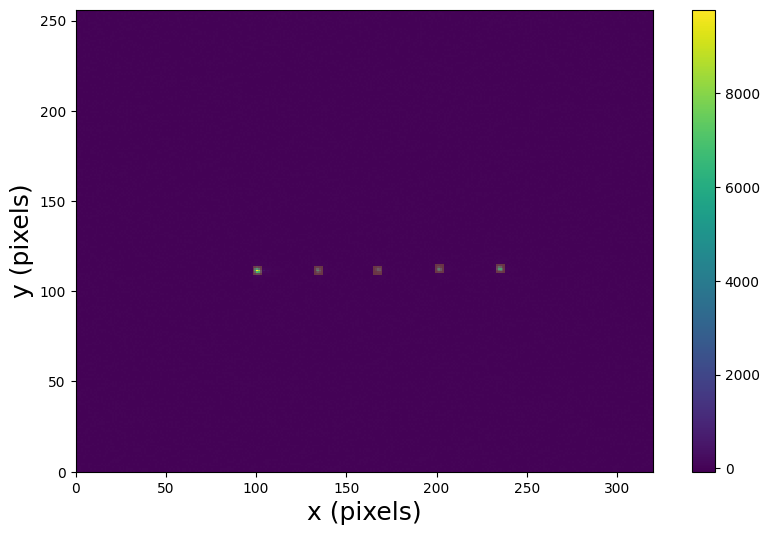

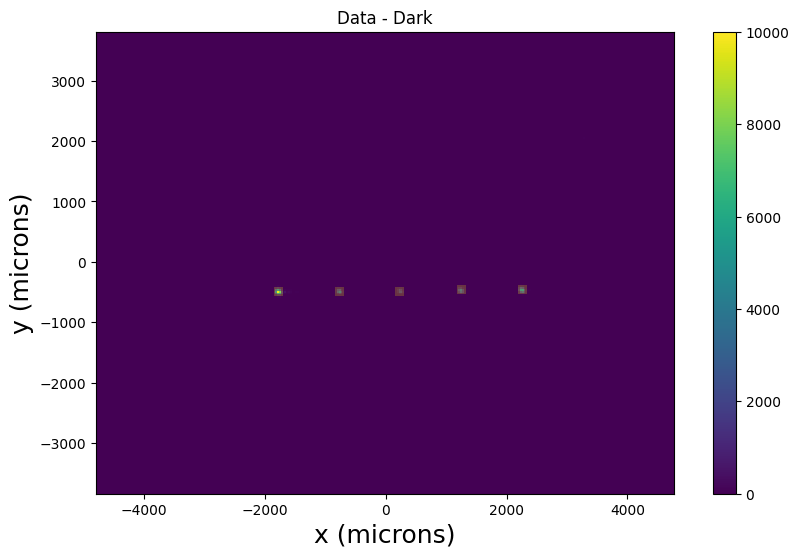

In [6]:
# Set XPOW voltages for reference image
xpow.apply_voltage(ATTEN_CHANNEL, 4.5)
xpow.apply_voltage(41, 5)
xpow.apply_voltage(19, 5)
xpow.apply_voltage(20, 8)

# Take reference data
tlx.set_voa(20)
tlx.laser_on()
time.sleep(10)
x, y, data, _ = cam.take_image()

# Take reference dark
tlx.laser_off()
time.sleep(2)
x, y, dark, _ = cam.take_image()
y_dim, x_dim = len(y), len(x)

# Construct a 3D array of boolean masks identifying the outputs
outputs_masks = PIC.build_output_mask(data-dark, 5)

# data, dark = PIC.remove_stripes(data, outputs_masks=outputs_masks), PIC.remove_stripes(dark)
data_reduce = data - dark

# Plot the reference data with the output mask
yellow_cmap = ListedColormap(['yellow'])
vmax = 10000

fig, ax = plt.subplots(1, 1, figsize=(10,6))
cbar_norm = colors.Normalize(vmin=0, vmax=vmax)  

cbar_norm = colors.Normalize(vmin=0, vmax=vmax)
im = ax.pcolormesh(x, y, data_reduce, norm=cbar_norm, zorder=0)
for mask in outputs_masks:
    masked_overlay = np.ma.masked_where(~mask, np.ones_like(mask))
    ax.pcolormesh(x, y, masked_overlay, cmap=yellow_cmap, alpha=0.2, zorder=1)
# ax.plot(x[coords[:, 1]], y[coords[:, 0]], 'r+')
fig.colorbar(im, ax=ax, fraction=0.05*y_dim/x_dim)
ax.set_xlabel('x (microns)', fontsize=18)
ax.set_ylabel('y (microns)', fontsize=18)
ax.set_title('Data - Dark')
ax.set_aspect('equal')
plt.show()

# Conduct a grid-search voltage scan

Data acquisition

In [8]:
filename_root = 'C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2025-12-15-Stability_test\\test_scan\\Device6a_I18_1x5Tricoupler'
channels = [20, 19, 41]
voltages = [np.arange(9, 12.1, 1), np.arange(9, 12.1, 1), np.arange(0, 2.1, 1)]

tlx.laser_on()
tlx.set_voa(20)
dats = PIC.voltage_scan(channels, 2, voltages, outputs_masks, filename_root, cam, xpow, tlx, dark_frame=dark)
np.savetxt(filename_root+"_dark.csv", dark, delimiter=",")

tlx.laser_off()

Laser set to on. VOA is 20.0.
VOA set to 20.0 dB.
Sent XPOW command: "CH:20:VOLT:9.0" to port "COM4".
COM4answer = {:20:VOLT:9.0:OK}
Sent XPOW command: "CH:20:VAL?" to port "COM4".
COM4answer = {20:0.000:0.0000}
Channel 20 set to 9.0 V.
Sent XPOW command: "CH:20:VAL?" to port "COM4".
COM4answer = {20:0.000:0.0000}
Sent XPOW command: "CH:19:VOLT:9.0" to port "COM4".
COM4answer = {:19:VOLT:9.0:OK}
Sent XPOW command: "CH:19:VAL?" to port "COM4".
COM4answer = {19:0.000:0.0000}
Channel 19 set to 9.0 V.
Sent XPOW command: "CH:19:VAL?" to port "COM4".
COM4answer = {19:0.000:0.0000}
Sent XPOW command: "CH:1:VOLT:0.0" to port "COM6".
COM6answer = {:1:VOLT:0.0:OK}
Sent XPOW command: "CH:1:VAL?" to port "COM6".
COM6answer = {1:0.000:0.0000}
Channel 41 set to 0.0 V.
Sent XPOW command: "CH:1:VAL?" to port "COM6".
COM6answer = {1:0.000:0.0000}
VOA set to 20.0 dB.
C:\Users\Pradip\Desktop\Sanny-PIC\2025-12-15-Stability_test\test_scan\Device6a_I18_1x5Tricoupler_Ch20_V9p00_Ch19_V9p00_Ch41_V0p00_bright.c

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2025-12-15-Stability_test\\test_scan\\Device6a_I18_1x5Tricoupler_Ch20_V9p00_Ch19_V9p00_Ch41_V0p00_bright.csv'

Static scan

In [3]:
import imageio, io
filename_root = 'C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2026-01-05-Active_splitters_imaging\\'

# Set XPOW voltages for reference image
xpow.apply_voltage(ATTEN_CHANNEL, 4.5)
xpow.apply_voltage(41, 5)
xpow.apply_voltage(19, 8)
xpow.apply_voltage(20, 8)

# Take reference dark
tlx.laser_off()
time.sleep(2)
x, y, dark_raw, _ = cam.take_image()
dark = PIC.remove_stripes(dark_raw)
y_dim, x_dim = len(y), len(x)

tlx.set_voa(20)
tlx.laser_on()
time.sleep(10)

frames = []
plot_lims = [[-3000, 3000], [-900, -300]]
for i in range(40):
    # Take reference data
    x, y, data, timestamp = cam.take_image(navg=1)
    if i == 0:
        timestamp_ref = np.copy(timestamp)
    t_diff = timestamp - timestamp_ref
    # time.sleep(5)    

    # Construct a 3D array of boolean masks identifying the outputs
    # outputs_masks = PIC.build_output_mask(data-dark_raw, 5, plot=False)

    # data = PIC.remove_stripes(data, outputs_masks=outputs_masks)
    data_reduce = data - dark

    # Plot the reference data with the output mask
    yellow_cmap = ListedColormap(['yellow'])

    fig, ax = plt.subplots(1, 1, figsize=(10,6))

    cbar_norm = colors.Normalize(vmin=0, vmax=10000)
    im = ax.pcolormesh(x, y, data_reduce, norm=cbar_norm, zorder=0)
    # for mask in outputs_masks:
    #     masked_overlay = np.ma.masked_where(~mask, np.ones_like(mask))
    #     ax.pcolormesh(x, y, masked_overlay, cmap=yellow_cmap, alpha=0.2, zorder=1)
    # ax.plot(x[coords[:, 1]], y[coords[:, 0]], 'r+')
    ax.set_xlim(plot_lims[0])
    ax.set_ylim(plot_lims[1])
    fig.colorbar(im, ax=ax, fraction=0.05*y_dim/x_dim)
    ax.set_xlabel('x (microns)', fontsize=18)
    ax.set_ylabel('y (microns)', fontsize=18)
    ax.set_title(f"t = {t_diff:.3f} s")
    ax.set_aspect('equal')

    buf = io.BytesIO()
    plt.savefig(buf, format='png', bbox_inches='tight', pad_inches=0)
    # plt.show()
    plt.close(fig)
    buf.seek(0)
    
    frames.append(imageio.imread(buf))

imageio.mimsave(filename_root+"static_scan_noDelay.gif", frames, fps=2, loop=0)

Sent XPOW command: "CH:39:VOLT:4.5" to port "COM4".
COM4answer = {:39:VOLT:4.5:OK}
Sent XPOW command: "CH:39:VAL?" to port "COM4".
COM4answer = {39:4.505:0.0000}
Channel 39 set to 4.5 V.
Sent XPOW command: "CH:1:VOLT:5" to port "COM6".
COM6answer = {:1:VOLT:5:OK}
Sent XPOW command: "CH:1:VAL?" to port "COM6".
COM6answer = {1:2.415:22.4877}
Channel 41 set to 5 V.
Sent XPOW command: "CH:19:VOLT:8" to port "COM4".
COM4answer = {:19:VOLT:8:OK}
Sent XPOW command: "CH:19:VAL?" to port "COM4".
COM4answer = {19:6.995:66.2707}
Channel 19 set to 8 V.
Sent XPOW command: "CH:20:VOLT:8" to port "COM4".
COM4answer = {:20:VOLT:8:OK}
Sent XPOW command: "CH:20:VAL?" to port "COM4".
COM4answer = {20:3.944:36.2406}
Channel 20 set to 8 V.
Laser set to off.
VOA set to 20.0 dB.
Laser set to on. VOA is 20.0.


Data reduction


In [ ]:
data_dir = 'C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2025-12-12-Calibration\\test_scan\\'
filename_root = 'Device6a_I18_1x5Tricoupler'
filename_dark = data_dir+filename_root+"_dark.csv"
filename_outputsBright = glob.glob(data_dir+filename_root+"*_outputsBright.npy")[0]
filename_outputsNull = glob.glob(data_dir+filename_root+"*_outputsNull.npy")[0]
voltages_ref, num_outputs = [9, 9, 0.5], 5
plot_lims = [[-3000, 3000], [-1000, 0]]

filename_x, filename_y = glob.glob(data_dir+filename_root+'*_x.csv')[0], glob.glob(data_dir+filename_root+'*_y.csv')[0]
x, y = np.loadtxt(filename_x), np.loadtxt(filename_y)
outputs_bright = np.load(filename_outputsBright)
outputs_null = np.load(filename_outputsNull)

# Voltages
filename_log = glob.glob(data_dir+filename_root+"*.log")[0]
channel_str = filename_log.split(data_dir+filename_root+'_')[-1].split('.log')[0]
channel_str = channel_str.split('_')
channels = [int(channel.split('Ch')[-1]) for channel in channel_str]

# Read voltages from data log
log = np.loadtxt(filename_log, delimiter=',')
with open(filename_log) as f:
    colnames = f.readline().strip().strip('# ').split(',')
log = np.core.records.fromarrays(log.T, names=colnames)

voltages = []
for channel in channels:
    voltages.append(np.sort(list(set(log['inputVoltage'+str(channel)]))))

# Extract outputs
output_bright_A, output_bright_B, output_bright_C, output_bright_D, ooutput_bright_E = outputs_bright
output_null_A, output_null_B, output_null_C, output_null_D, ooutput_null_E = outputs_null
voltages_PS1, voltages_PS2, voltages_PS3 = voltages
nulls = 10*np.log10(output_null_C/(output_bright_B + output_bright_C + output_bright_D))

# Plot 2D maps of null measurements scanning through PS1 (x-axis), PS2 (y_axis), and PS3 (frame)
frames = []
for i3, v3 in enumerate(voltages_PS3):
    fig, ax = plt.subplots(1, 1, figsize=(9,9))
    
    cbar_norm = colors.Normalize(vmin=-35, vmax=0) 
    im = plt.pcolormesh(voltages_PS1, voltages_PS2, nulls[i3,:,:], norm=cbar_norm)
    cbar = fig.colorbar(im, ax=ax)
    cbar.ax.set_title('dB', fontsize=14)
    ax.set_aspect('equal')
    plt.xlabel('Voltage PS1 (V)')
    plt.ylabel('Voltage PS2 (V)')
    plt.title(f"Voltage PS3: {v3:.2f} V")

    buf = io.BytesIO()
    plt.savefig(buf, format='png', bbox_inches='tight', pad_inches=0)
    plt.show()
    plt.close(fig)
    buf.seek(0)
    
    frames.append(imageio.imread(buf))

imageio.mimsave(data_dir+filename_root+"_null.gif", frames, fps=1, loop=0)

There's a lot more in the `PIC_lib.py` Python library, `XenicsImaging_Acquire_20251113.ipynb` notebook, and `XenicsImaging_Reduce_20251121.ipynb` notebook that might be useful. Feel free to message me with questions but my responses may be very delayed until after Christmas! Sorry I couldn't add more, I've run out of time!

# Close connection to hardware

In [4]:
tlx.laser_off()
tlx.close()

zaber.close()

xpow.close()

cam.close()

Laser set to off.
Laser set to off.
Connection to TLX2 laser closed.
Connection to Zabers closed.
Sent XPOW command: "CH:1:VOLT:0" to port "COM4".
COM4answer = {:1:VOLT:0:OK}
Sent XPOW command: "CH:1:CUR:100" to port "COM4".
COM4answer = {1:CUR:100:OK}
Sent XPOW command: "CH:2:VOLT:0" to port "COM4".
COM4answer = {:2:VOLT:0:OK}
Sent XPOW command: "CH:2:CUR:100" to port "COM4".
COM4answer = {2:CUR:100:OK}
Sent XPOW command: "CH:3:VOLT:0" to port "COM4".
COM4answer = {:3:VOLT:0:OK}
Sent XPOW command: "CH:3:CUR:100" to port "COM4".
COM4answer = {3:CUR:100:OK}
Sent XPOW command: "CH:4:VOLT:0" to port "COM4".
COM4answer = {:4:VOLT:0:OK}
Sent XPOW command: "CH:4:CUR:100" to port "COM4".
COM4answer = {4:CUR:100:OK}
Sent XPOW command: "CH:5:VOLT:0" to port "COM4".
COM4answer = {:5:VOLT:0:OK}
Sent XPOW command: "CH:5:CUR:100" to port "COM4".
COM4answer = {5:CUR:100:OK}
Sent XPOW command: "CH:6:VOLT:0" to port "COM4".
COM4answer = {:6:VOLT:0:OK}
Sent XPOW command: "CH:6:CUR:100" to port "COM4".
